<a href="https://colab.research.google.com/github/tn652006-droid/MachineLearning/blob/main/Tuan3/BTVN/ML_T3_BTVN_B2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Kich thuoc: (1797, 64)
So loai chu so: 10
Gia tri thieu: 0


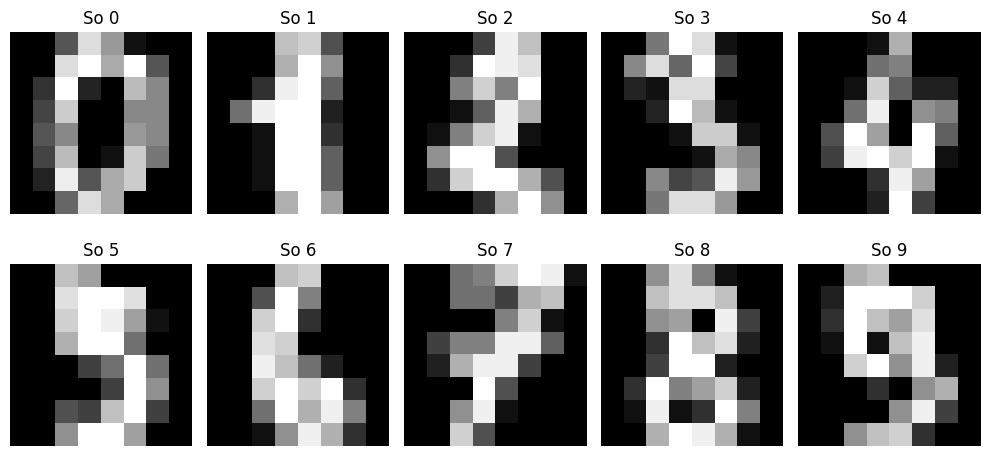


MO HINH: Gaussian Naive Bayes
Accuracy: 0.7416666666666667
              precision    recall  f1-score   support

           0       0.97      0.92      0.94        36
           1       0.56      0.83      0.67        36
           2       0.76      0.37      0.50        35
           3       1.00      0.51      0.68        37
           4       1.00      0.53      0.69        36
           5       0.89      0.92      0.91        37
           6       0.90      0.97      0.93        36
           7       0.69      0.97      0.80        36
           8       0.41      0.74      0.53        35
           9       0.92      0.64      0.75        36

    accuracy                           0.74       360
   macro avg       0.81      0.74      0.74       360
weighted avg       0.81      0.74      0.74       360


MO HINH: Decision Tree
Accuracy: 0.8138888888888889
              precision    recall  f1-score   support

           0       0.92      0.97      0.95        36
           1       

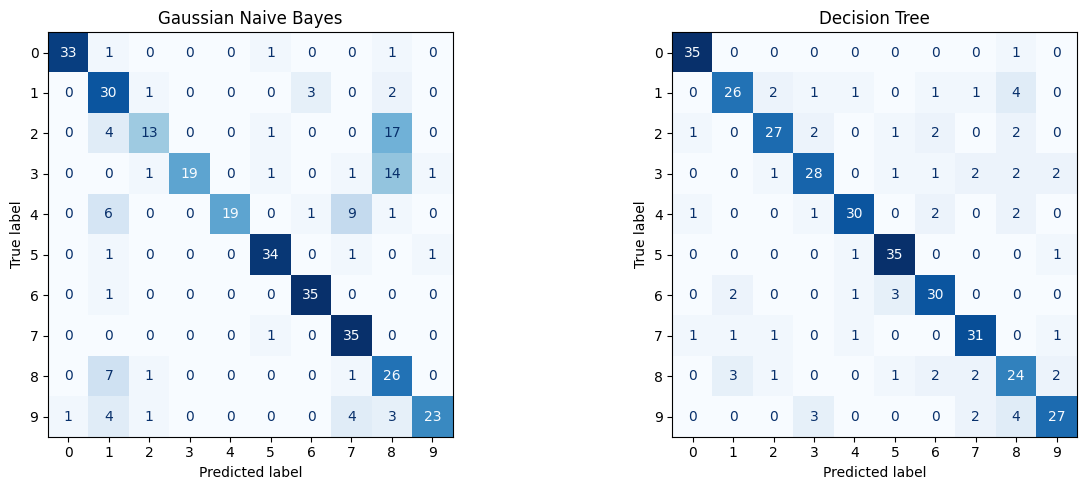


BANG SO SANH:
             Mo hinh  Accuracy
Gaussian Naive Bayes  0.741667
       Decision Tree  0.813889


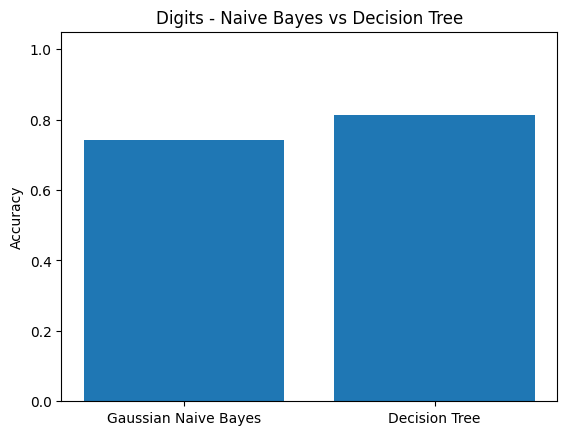


10 CHU SO DU DOAN:
Thuc te: 5 | Du doan: 5
Thuc te: 2 | Du doan: 2
Thuc te: 8 | Du doan: 8
Thuc te: 1 | Du doan: 1
Thuc te: 7 | Du doan: 7
Thuc te: 2 | Du doan: 2
Thuc te: 6 | Du doan: 6
Thuc te: 2 | Du doan: 5
Thuc te: 6 | Du doan: 6
Thuc te: 5 | Du doan: 5


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score, classification_report,
    ConfusionMatrixDisplay
)

# 1. Nap du lieu Digits
digits = load_digits()
X = digits.data
y = digits.target

print("Kich thuoc:", X.shape)
print("So loai chu so:", len(np.unique(y)))
print("Gia tri thieu:", pd.DataFrame(X).isna().sum().sum())

# 2. Hien thi 10 chu so mau
fig, axes = plt.subplots(2, 5, figsize=(10, 5))
for ax, i in zip(axes.ravel(), range(10)):
    ax.imshow(digits.images[i], cmap="gray")
    ax.set_title(f"So {y[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

# 3. Chia 80% train, 20% test
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# 4. Tao hai mo hinh
models = {
    "Gaussian Naive Bayes": Pipeline([
        ("scale", StandardScaler()),
        ("model", GaussianNB())
    ]),
    "Decision Tree": Pipeline([
        ("scale", StandardScaler()),
        ("model", DecisionTreeClassifier(
            max_depth=12, random_state=42
        ))
    ])
}

# 5. Huan luyen va danh gia
results = []
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, (name, model) in zip(axes, models.items()):
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    acc = accuracy_score(y_test, pred)
    results.append({
        "Mo hinh": name,
        "Accuracy": acc
    })

    print("\nMO HINH:", name)
    print("Accuracy:", acc)
    print(classification_report(
        y_test, pred, zero_division=0
    ))

    ConfusionMatrixDisplay.from_predictions(
        y_test, pred,
        ax=ax,
        cmap="Blues",
        colorbar=False
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

# 6. Bang so sanh Accuracy
df = pd.DataFrame(results)
print("\nBANG SO SANH:")
print(df.to_string(index=False))

plt.bar(df["Mo hinh"], df["Accuracy"])
plt.ylim(0, 1.05)
plt.ylabel("Accuracy")
plt.title("Digits - Naive Bayes vs Decision Tree")
plt.show()

# 7. Du doan 10 chu so dau trong tap kiem tra
best_name = df.loc[df["Accuracy"].idxmax(), "Mo hinh"]
best_model = models[best_name]

pred_10 = best_model.predict(X_test[:10])

print("\n10 CHU SO DU DOAN:")
for i in range(10):
    print(
        "Thuc te:", y_test[i],
        "| Du doan:", pred_10[i]
    )
